<a href="https://colab.research.google.com/github/JimenaH12/P2P/blob/main/IIP_JHern%C3%A1ndez_B73729.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# II Parcial - Complemento Computacional

## Jimena Hernándes T - B73729

**Herramienta utilizada:** Google Colaboratory (Google Colab)  
**Lenguaje:** Python 3


**Enlace para acceder al código**: https://colab.research.google.com/drive/1Jo89X8V8PEgtFWVQOK6tqTA3an3j76kP?usp=sharing


---



## Campo electrostático entre dos conductores esféricos

**Enunciado**: Se tienen dos esferas conductoras $c_1$ y $c_2$ de radios $r_1$ y $r_2$, cuyos centros $O_1$ y $O_2$ están separados por una distancia $d$. Se mantienen a potenciales $\Phi_1$ y $\Phi_2$ respectivamente. Determine el campo en las cercanías de las esferas al mantener los potenciales.

---

### Método de Imagen

Al tener una esfera de radio $r$ centrada en el origen a un potencial $\Phi$, se coloca una carga $q_0 = 4\pi\varepsilon_0 r \Phi$ en su centro, pero esa carga distorsiona el potencial en la otra esfera contínua, así que hay que añadir una carga imagen en esa otra esfera, y así sucesivamente de manera infinita.


Se coloca $O_1$ en el origen y $O_2$ en $x = d$.

$$q_1^{(0)} = 4\pi\varepsilon_0\, r_1\, \Phi_1, \quad b_1^{(0)} = 0$$
$$q_2^{(0)} = 4\pi\varepsilon_0\, r_2\, \Phi_2, \quad b_2^{(0)} = 0$$


**Iteración:** la carga de la esfera 1 induce carga imagen en esfera 2 y viceversa
$$q_2^{(n)} = -\frac{r_2}{d - b_1^{(n-1)}}\,q_1^{(n-1)}, \qquad b_2^{(n)} = d - \frac{r_2^2}{d - b_1^{(n-1)}}$$
$$q_1^{(n)} = -\frac{r_1}{d - b_2^{(n)}}\,q_2^{(n)}, \qquad b_1^{(n)} = \frac{r_1^2}{d - b_2^{(n)}}$$


In [66]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import Normalize

# PARÁMETROS DEL SISTEMA: PRUEBA 1

r1 = 2.5        # radio esfera 1
r2 = 5          # radio esfera 2
d  = 20         # distancia entre centros (d > r1 + r2)
Phi1 = 5        # potencial esfera 1
Phi2 = -5       # potencial esfera 2
N_images = 10   # número de cargas imagen por esfera (enunciado)

eps0 = 8.854e-12  # [F/m]

In [67]:
# CÁLCULO DE LAS CARGAS IMAGEN

# Centro de esfera 1: x=0,  centro de esfera 2: x=d
# Las posiciones b_i se miden desde el centro de cada esfera hacia el interior, sobre el eje x que une los centros.


# Calcula las cargas en cada esfera usando la sucesión
def compute_image_charges(r1, r2, d, Phi1, Phi2, N):

    charges = []  # lista de (q, x)

    # Cargas iniciales (centro de cada esfera)
    q1 = r1 * Phi1
    b1 = 0.0         # posición relativa al centro O_1

    q2 = r2 * Phi2
    b2 = 0.0         # posición relativa al centro O_2 (x = d + b2)

    charges.append((q1, b1))               # posición global: b1
    charges.append((q2, d + b2))           # posición global: d + b2 = d

    for n in range(N):
        # Imagen de q1 (ubicada en b1 desde O1) dentro de la esfera 2
        # distancia desde O2 a la carga q1 = d - b1
        dist21 = d - b1
        q2_new  = -(r2 / dist21) * q1
        b2_new  = -(r2**2 / dist21)       # negativo = hacia O2 desde el lado de O1

        # Imagen de q2 (ubicada en b2 desde O2) dentro de la esfera 1
        # distancia desde O1 a la carga q2 = d + b2_new  (b2_new < 0)
        dist12 = d + b2_new
        q1_new  = -(r1 / dist12) * q2_new
        b1_new  =  (r1**2 / dist12)

        # Actualizar
        b1, q1 = b1_new, q1_new
        b2, q2 = b2_new, q2_new

        # Agregar cargas en coordenadas globales
        charges.append((q1, b1))           # dentro de esfera 1
        charges.append((q2, d + b2))       # dentro de esfera 2 (b2 < 0)

    return charges


charges = compute_image_charges(r1, r2, d, Phi1, Phi2, N_images)

print(f"Total de cargas imagen calculadas: {len(charges)}")
#print("\nCargas (q, x_global):")
for i, (q, x) in enumerate(charges[:22]):
    print(f"  [{i}]  q = {q:+.6f},  x = {x:.6f}")

Total de cargas imagen calculadas: 22
  [0]  q = +12.500000,  x = 0.000000
  [1]  q = -25.000000,  x = 20.000000
  [2]  q = +0.416667,  x = 0.333333
  [3]  q = -3.125000,  x = 18.750000
  [4]  q = +0.014140,  x = 0.333710
  [5]  q = -0.105932,  x = 18.728814
  [6]  q = +0.000480,  x = 0.333711
  [7]  q = -0.003595,  x = 18.728789
  [8]  q = +0.000016,  x = 0.333711
  [9]  q = -0.000122,  x = 18.728789
  [10]  q = +0.000001,  x = 0.333711
  [11]  q = -0.000004,  x = 18.728789
  [12]  q = +0.000000,  x = 0.333711
  [13]  q = -0.000000,  x = 18.728789
  [14]  q = +0.000000,  x = 0.333711
  [15]  q = -0.000000,  x = 18.728789
  [16]  q = +0.000000,  x = 0.333711
  [17]  q = -0.000000,  x = 18.728789
  [18]  q = +0.000000,  x = 0.333711
  [19]  q = -0.000000,  x = 18.728789
  [20]  q = +0.000000,  x = 0.333711
  [21]  q = -0.000000,  x = 18.728789


In [68]:
# Campo Eléctrico -> Fórmula: E = -grad(V)
# V = sum_i q_i / |r - r_i|

# Calcula Ex, Ey en una malla 2D dado el conjunto de cargas y devuelve (Ex, Ey) como arrays del mismo shape que X, Y
def electric_field(X, Y, charges):

    Ex = np.zeros_like(X)
    Ey = np.zeros_like(Y)
    for q, xc in charges:
        dx = X - xc
        dy = Y        # cargas en y=0
        r2_ = dx**2 + dy**2
        r2_[r2_ < 1e-6] = np.inf   # evitar singularidades
        Ex += q * dx / r2_**1.5
        Ey += q * dy / r2_**1.5
    return Ex, Ey


#Potencial escalar en la malla
def potential(X, Y, charges):
    V = np.zeros_like(X)
    for q, xc in charges:
        dx = X - xc
        dy = Y
        r_ = np.sqrt(dx**2 + dy**2)
        r_[r_ < 1e-6] = np.inf
        V += q / r_
    return V


# Excluir el interior de las esferas
def exterior_mask(X, Y, r1, r2, d, margin=0.02):# Devuelve True donde el punto está fuera de ambas esferas
    inside1 = (X**2 + Y**2) < (r1 + margin)**2
    inside2 = ((X - d)**2 + Y**2) < (r2 + margin)**2
    return ~inside1 & ~inside2

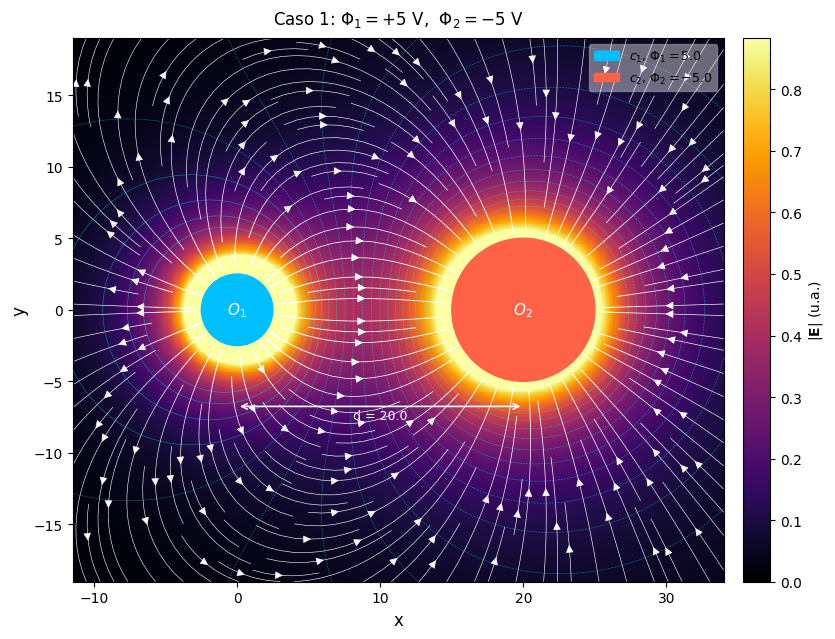

In [69]:
# CASO 1:  Phi1 = +5,  Phi2 = -5  (mismo valor, pero potenciales opuestos)


def plot_field_lines(r1, r2, d, Phi1, Phi2, N_images=10, ax=None, title=""):
    charges = compute_image_charges(r1, r2, d, Phi1, Phi2, N_images)

    # Malla
    margin = max(r1, r2) * 1.8
    x = np.linspace(-r1 - margin, d + r2 + margin, 600)
    y = np.linspace(-(d/2 + margin), (d/2 + margin), 600)
    X, Y = np.meshgrid(x, y)

    mask = exterior_mask(X, Y, r1, r2, d)

    Ex, Ey = electric_field(X, Y, charges)
    V      = potential(X, Y, charges)

    # Exclusión del interior de las eferas
    Ex_m = np.where(mask, Ex, np.nan)
    Ey_m = np.where(mask, Ey, np.nan)
    V_m  = np.where(mask, V, np.nan)

    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 6))

    # Magnitud del campo
    E_mag = np.sqrt(Ex_m**2 + Ey_m**2)
    vmax  = np.nanpercentile(E_mag, 97)

    im = ax.pcolormesh(X, Y, E_mag, cmap='inferno', shading='auto',
                       norm=Normalize(0, vmax), zorder=1)
    plt.colorbar(im, ax=ax, label=r'$|\mathbf{E}|$ (u.a.)', pad=0.02)

    # Líneas de campo
    speed = np.sqrt(Ex_m**2 + Ey_m**2)
    lw    = 1.0 * speed / (np.nanmax(speed) + 1e-12) + 0.4

    ax.streamplot(x, y, Ex_m, Ey_m,
                  color='white',
                  density=1.6,
                  linewidth=lw,
                  arrowsize=1.2,
                  zorder=2)

    # Líneas equipotenciales
    levels = np.linspace(np.nanpercentile(V_m, 5), np.nanpercentile(V_m, 95), 18)
    ax.contour(X, Y, V_m, levels=levels, colors='cyan', linewidths=0.4,
               alpha=0.5, zorder=3)

    # Esferas
    circle1 = plt.Circle((0, 0), r1, color='deepskyblue', zorder=4, label=f'$c_1$, $\\Phi_1={Phi1}$')
    circle2 = plt.Circle((d, 0), r2, color='tomato',    zorder=4, label=f'$c_2$, $\\Phi_2={Phi2}$')
    ax.add_patch(circle1)
    ax.add_patch(circle2)

    # Etiquetas de centros
    ax.annotate(f'$O_1$', (0, 0), fontsize=11, ha='center', va='center',
                color='white', fontweight='bold', zorder=5)
    ax.annotate(f'$O_2$', (d, 0), fontsize=11, ha='center', va='center',
                color='white', fontweight='bold', zorder=5)

    # Barra de separación d
    y_bar = -(r1 + r2) * 0.9
    ax.annotate('', xy=(d, y_bar), xytext=(0, y_bar),
                arrowprops=dict(arrowstyle='<->', color='white', lw=1.2))
    ax.text(d/2, y_bar - 0.15, f'd = {d}', ha='center', va='top',
            color='white', fontsize=9)

    ax.set_aspect('equal')
    ax.set_xlabel('x', fontsize=12)
    ax.set_ylabel('y', fontsize=12)
    ax.set_title(title, fontsize=12, pad=10)
    ax.legend(loc='upper right', fontsize=9, framealpha=0.4)
    ax.set_xlim(x[0], x[-1])
    ax.set_ylim(y[0], y[-1])

    return ax


# Figura
fig1, ax1 = plt.subplots(figsize=(10, 6.5))
plot_field_lines(r1=2.5, r2=5.0, d=20.0,
                 Phi1=+5.0, Phi2=-5.0,
                 N_images=20, ax=ax1,
                 title=r'Caso 1: $\Phi_1 = +5$ V,  $\Phi_2 = -5$ V')
plt.tight_layout()
plt.show()

## Análisis de resultados

La figura muestra el campo electrostático que se obtiene de una diferencia de potencial de $\Phi_1 = +5V$ y $\Phi_2=-5 V$. El color de fondo representa la intensidad de magnitud del campo $|\mathbf{E}|$, el color amarrillo indica campo intenso, mientras que el morado oscuro y negro refleja el decaimiento.

Las líneas blancas con flechas son las **líneas de campo eléctrico**, que parten en este caso de $c_1$ (potencial positivo) hasta a $c_2$ (potencial negativo). Esto es consistente con la dirección del campo de mayor a menor potencial. Además, la mayor densidad de líneas blancas entre ambas esferas evidencia que el campo es más intenso en esa zona, lo cual es esperado por la atracción entre las cargas inducidas de signo opuesto.

Finalmente, Las curvas punteadas de color azul que rodean a cada esfera son las **superficies equipotenciales**, y se denota que son perpendiculares a las
líneas de campo en todo punto, tal como la teoría.


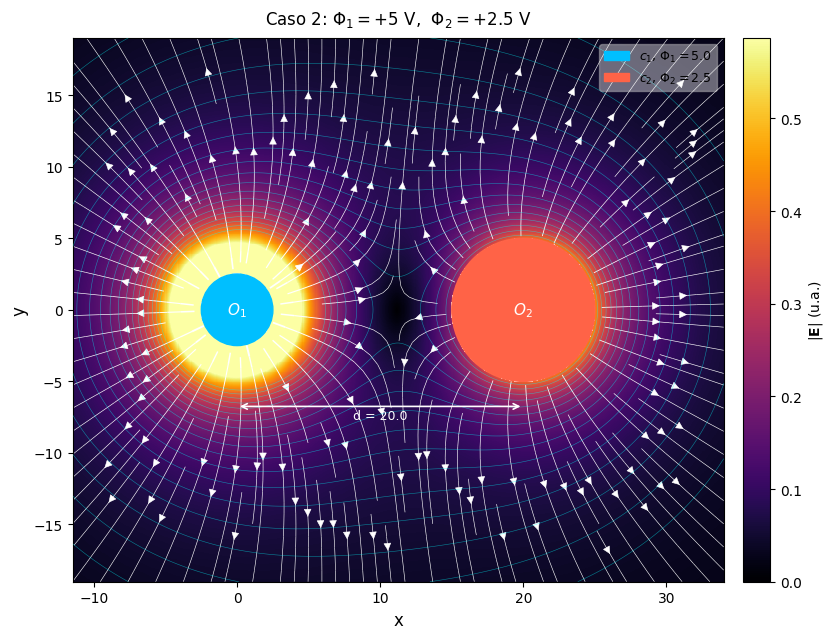

In [70]:
# CASO 2:  Phi1 = +5,  Phi2 = +2.5  (diferente valor, pero ambos positivos)

fig2, ax2 = plt.subplots(figsize=(10, 6.5))
plot_field_lines(r1=2.5, r2=5.0, d=20.0,
                 Phi1=+5.0, Phi2=+2.5,
                 N_images=10, ax=ax2,
                 title=r'Caso 2: $\Phi_1 = +5$ V,  $\Phi_2 = +2.5$ V')
plt.tight_layout()
plt.show()

## Análisis de resultados

El cambio respecto a la figura anterior es que ahora **ambas esferas están a potencial positivo**. Debido a esto, las líneas de campo ya no conectan $c_1$ con $c_2$, si no que salen de ambas superficies y se
dirigen hacia el infinito.

En la región entre las esferas se forma una zona oscura (campo nulo) donde los aportes de ambas fuentes se cancelan parcialmente. Esto corresponde
a un **punto de equilibrio** del campo eléctrico. Las equipotenciales también cambian un poco, ya no se conectan al acercarse al centro, más bien cada una se cierra alrededor de una esfera.